In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import xgboost as xgb

## Data Integration


Load Data Echocardiogram

In [2]:
# 1. Read data directly from the UCI ML Repository with proper handling of missing values
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/echocardiogram/echocardiogram.data"
columns = [
    'Survival', 'StillAlive', 'AgeAtHeartAttack', 'PericardialEffusion',
    'FractionalShortening', 'Epss', 'Lvdd', 'WallMotionScore',
    'WallMotionIndex', 'Mult', 'Name', 'Group', 'AliveAt1'
]

# Load data with na_values='?' to automatically detect missing values
data_raw = pd.read_csv(url, names=columns, na_values='?', on_bad_lines='skip')

# Drop rows where the main target (StillAlive) is missing
data_clean = data_raw.dropna(subset=['StillAlive']).copy()

# Drop columns that are not directly relevant to clinical medical modeling
data_clean = data_clean.drop(columns=['Name', 'Group', 'AliveAt1'], errors='ignore')

print(f"Final shape: {data_clean.shape}")
data_clean.head()

Final shape: (131, 10)


,Survival,StillAlive,AgeAtHeartAttack,PericardialEffusion,FractionalShortening,Epss,Lvdd,WallMotionScore,WallMotionIndex,Mult
0,11.0,0,71.0,0,0.260,9.000,4.600,14.0,1.00,1.000
1,19.0,0,72.0,0,0.380,6.000,4.100,14.0,1.70,0.588
2,16.0,0,55.0,0,0.260,4.000,3.420,14.0,1.00,1.000
3,57.0,0,60.0,0,0.253,12.062,4.603,16.0,1.45,0.788
4,19.0,1,57.0,0,0.160,22.000,5.750,18.0,2.25,0.571


##Data Transformation

In [3]:
discrete_features = ['PericardialEffusion']
continuous_features = data_clean.drop(columns=['PericardialEffusion', 'StillAlive']).columns
label = ['StillAlive']

print(continuous_features)

Index(['Survival', 'AgeAtHeartAttack', 'FractionalShortening', 'Epss', 'Lvdd',
       'WallMotionScore', 'WallMotionIndex', 'Mult'],
      dtype='object')


In [4]:
data_clean.shape

(131, 10)

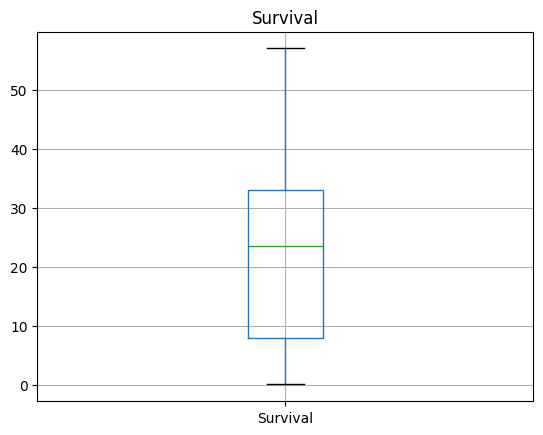

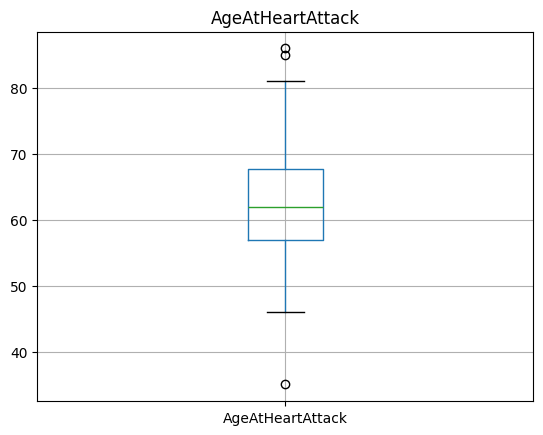

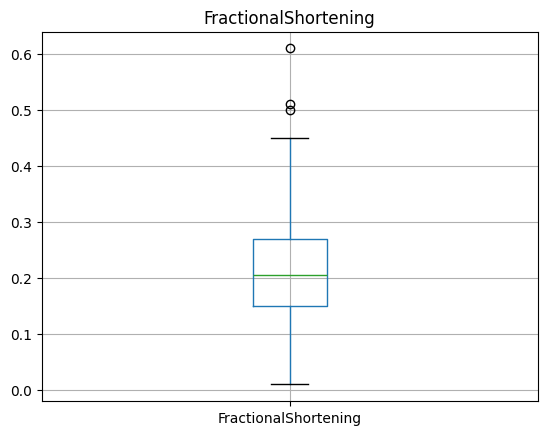

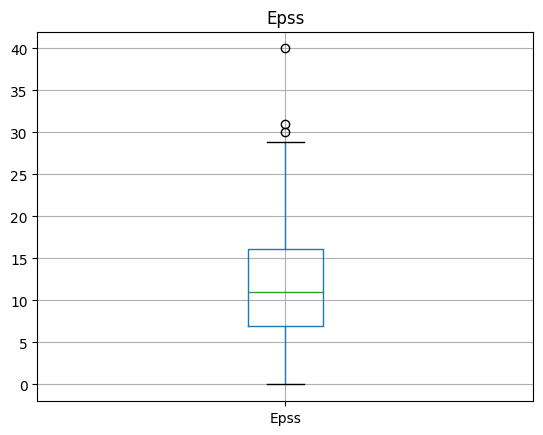

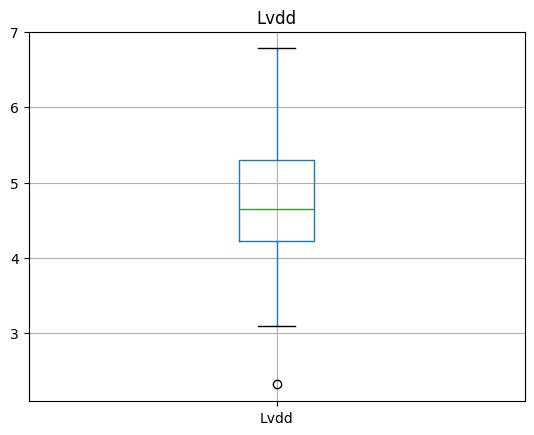

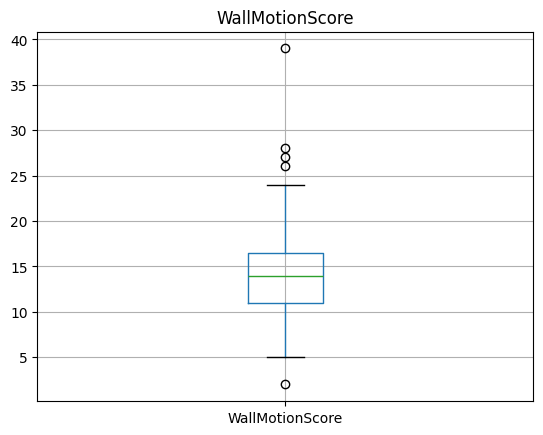

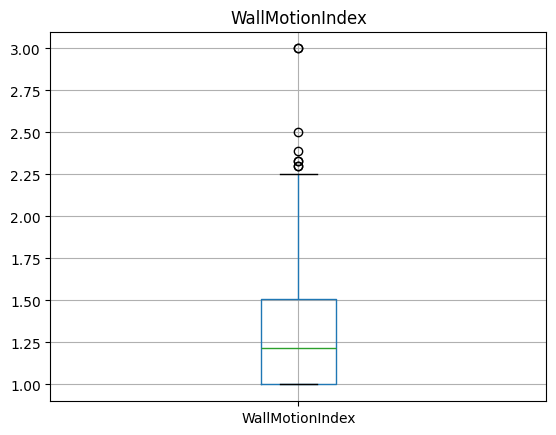

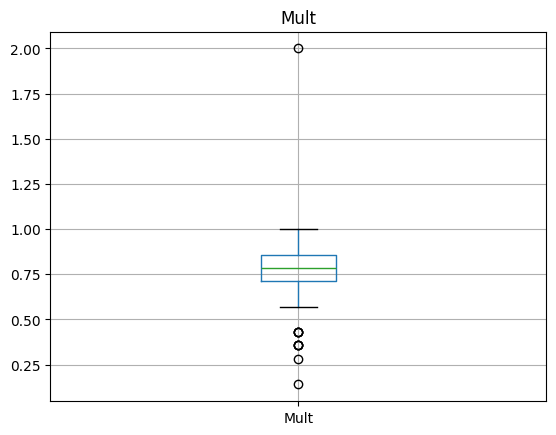

In [5]:
for feature in continuous_features:
    data_clean.boxplot(feature)
    plt.title(feature)
    plt.show()

## Data Transformation and Data Discretization

In [6]:
features_with_outliers = ['WallMotionScore', 'WallMotionIndex', 'Mult']

In [7]:
data_clean.shape

(131, 10)

In [8]:
data_clean.isnull().sum()

,0
Survival,1
StillAlive,0
AgeAtHeartAttack,5
PericardialEffusion,0
FractionalShortening,7
Epss,14
Lvdd,10
WallMotionScore,3
WallMotionIndex,1
Mult,3


In [9]:
data_clean.shape

(131, 10)

## Model Training and Evaluation

In [10]:
# 1. Prepare clean features without target leakage (drop 'Survival')
X_final = data_clean.drop(columns=['StillAlive', 'Survival'], errors='ignore')
y_final = data_clean['StillAlive']

# Identify column types
discrete_cols = ['PericardialEffusion']
num_cols = [col for col in X_final.columns if col not in discrete_cols]

# 2. Define Preprocessing Pipeline
preprocessor_final = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols)
], remainder='passthrough')

# 3. Define CV Scheme
cv_final = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)

# 4. Perform secure XGBoost Hyperparameter Tuning inside the Pipeline
xgb_pipeline = Pipeline([
    ('pre', preprocessor_final),
    ('clf', xgb.XGBClassifier(random_state=0))
])

param_distributions = {
    'clf__learning_rate': [0.01, 0.05, 0.1, 0.2, 0.3],
    'clf__max_depth': [3, 4, 5, 6, 7],
    'clf__min_child_weight': [1, 3, 5],
    'clf__gamma': [0.0, 0.1, 0.2, 0.3, 0.4]
}

tuned_xgb_search = RandomizedSearchCV(
    xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    cv=cv_final,
    scoring='accuracy',
    n_jobs=-1,
    random_state=0
)
tuned_xgb_search.fit(X_final, y_final)

best_xgb_model = tuned_xgb_search.best_estimator_['clf']
print("Best XGBoost Hyperparameters:", tuned_xgb_search.best_params_)

Best XGBoost Hyperparameters: {'clf__min_child_weight': 5, 'clf__max_depth': 6, 'clf__learning_rate': 0.3, 'clf__gamma': 0.3}


In [11]:
# 5. Evaluate All Models Fairly (No Target Leakage)
models_final = {
    'Baseline (Most Frequent)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=500, class_weight='balanced', random_state=0),
    'Decision Tree': DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=0),
    'Random Forest': RandomForestClassifier(max_depth=4, class_weight='balanced', random_state=0),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, random_state=0),
    'Tuned XGBoost': best_xgb_model
}

final_results = []

for name, model in models_final.items():
    pipeline_eval = Pipeline([
        ('pre', preprocessor_final),
        ('clf', model)
    ])

    scores = cross_validate(pipeline_eval, X_final, y_final, cv=cv_final, scoring=['accuracy', 'f1', 'roc_auc'], n_jobs=-1)

    final_results.append({
        'Model': name,
        'Accuracy (%)': round(scores['test_accuracy'].mean() * 100, 2),
        'F1-Score (%)': round(scores['test_f1'].mean() * 100, 2),
        'ROC-AUC (%)': round(scores['test_roc_auc'].mean() * 100, 2)
    })

df_final_performance = pd.DataFrame(final_results)
display(df_final_performance)

,Model,Accuracy (%),F1-Score (%),ROC-AUC (%)
0,Baseline (Most Frequent),67.18,0.00,50.00
1,Logistic Regression,72.07,59.66,76.56
2,Decision Tree,61.07,50.82,62.48
3,Random Forest,70.09,53.51,74.65
4,Gradient Boosting,65.65,43.68,66.46
5,Tuned XGBoost,69.19,46.19,72.31


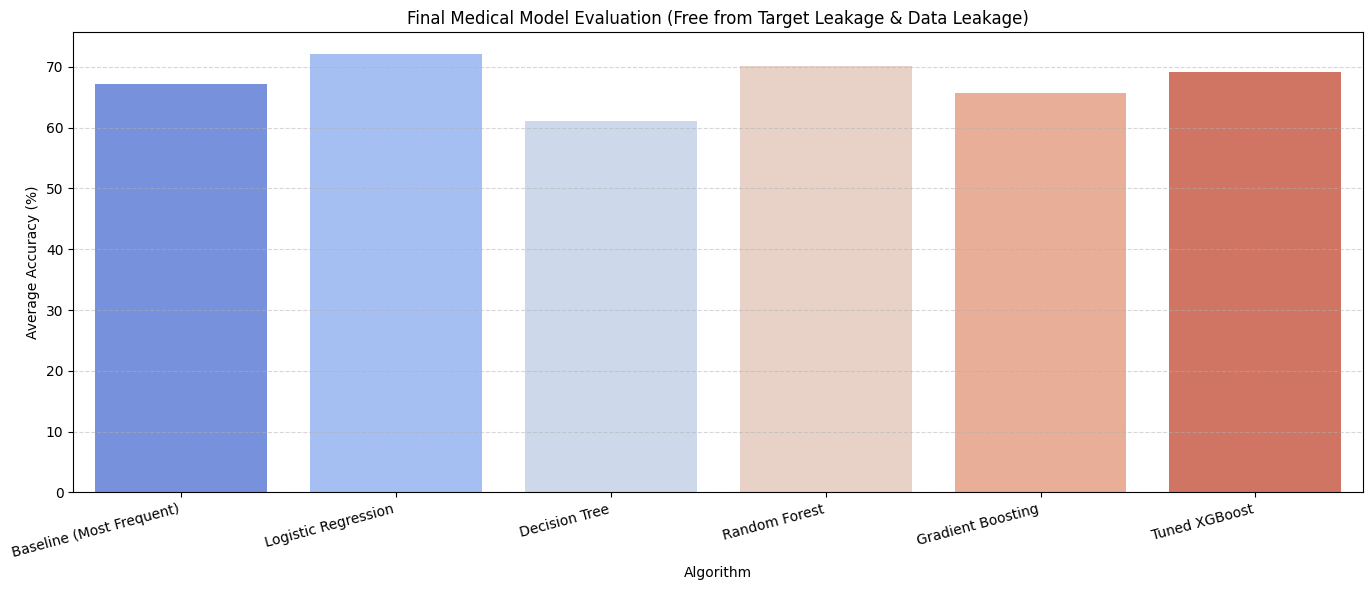

In [12]:
# 6. Visualize Final Metrics Comparison
plt.figure(figsize=(14, 6))
sns.barplot(x='Model', y='Accuracy (%)', data=df_final_performance, hue='Model', palette='coolwarm', legend=False)
plt.title('Final Medical Model Evaluation (Free from Target Leakage & Data Leakage)')
plt.ylabel('Average Accuracy (%)')
plt.xlabel('Algorithm')
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()